## The Purpose :
this notebook is to simulate the two spin dynamics when only one THz pulse is activated.

In [1]:
%load_ext autoreload
%autoreload 2

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

In [2]:
from two_spin_dynamics.pulses import single_thz_pulse, d2gdt2_pulse
from two_spin_dynamics.spin_hamiltonian import (
    effective_fields_no_external,
    energy,
)

### Hamiltonian Paramters Setup
temperature is very important ! Because ground state configuration at low temperature is different from ground state configuration at high temperature. If we use a wrong configuration, then the small angle expansion is invalid and there will be numerical instability.

In [3]:
# parameters set up
Stot = 5/2 # dimensionless
nn = 6
Jex = 4.6 # meV
Da = 0
Db = 0.1066 # meV # Dvec only has non-zero y-component ( along b axis )
Dc = 0
Ka = 0.00905 # meV
Tk = 300 # Kelvin : 15 ( Kc > Ka ) / 60 / 110 / 160 / 300 (Kc < Ka )
Kc = 0.9847 / (Tk + 62.38) + 0.00265 # meV

# canted angle
beta0 = 0.5 * np.arctan2(nn * Db, nn * Jex + Ka - Kc)

print("the canted angle is beta0 = ", beta0 * 180 / np.pi, " deg")
print("the net magnetization is ", 2 * Stot * np.sin(beta0))
print("is the canted angle small enough to use the small angle approximation ? ", beta0 < 0.1 * np.pi)

the canted angle is beta0 =  0.6636763793979438  deg
the net magnetization is  0.05791539480012153
is the canted angle small enough to use the small angle approximation ?  True


In [4]:
Kc,Ka

(0.005367313317512004, 0.00905)

In [5]:
# dict for Hamiltonian parameters
Ham_params = {
    "nn": nn,
    "Stot": Stot,
    "Jex": Jex,
    "Dvec": np.array([Da, Db, Dc]),
    "Kvec": np.array([Ka, 0.0, Kc]),
}

Ham_params["Dvec"]

array([0.    , 0.1066, 0.    ])

### Pulse Parameters Set up

In [51]:
# Plot THz_gaussian_pulse over time grid
sigma = 0.6 # unit is ps
t0 = 0.0 # unit is ps
# halfwidth = 5 * sigma
start_time = t0 - 5
end_time = t0 + 15
h_peak = 0.15 # unit is Tesla, this is the experimental value
num_points = 2000
tlist = np.linspace(start_time, end_time, num_points)

In [52]:
from two_spin_dynamics.plotting import plot_pulse

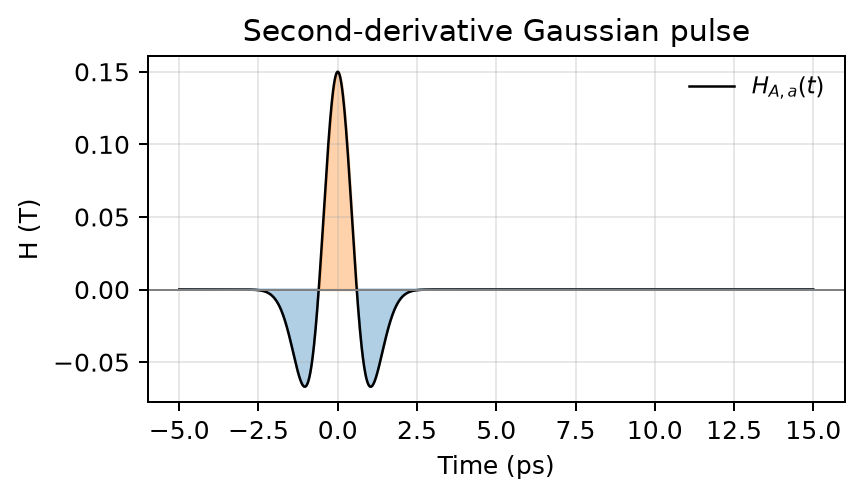

In [53]:
# Single THz pulse: a linearly polarized field along the a (x) axis.
pulse_params = {
    "shape_params": {"t0": t0, "sigma": sigma, "h_peak": h_peak},
    "polarization": np.array([1.0, 0.0, 0.0]), # along the crystalline a direction, drive qFM mode
    "state": "on",
}

# H_single[i] is the external field vector (H_a, H_b, H_c) at tlist[i].
H_single = np.array([single_thz_pulse(t, pulse_params) for t in tlist])

# shift time

# Plot the a-axis component, which equals the scalar pulse amplitude here.
ax = plot_pulse(tlist, H_single[:, 0], label=r"$H_{A,a}(t)$")
plt.show()

In [54]:
from two_spin_dynamics.spectral_analysis import rfft_spectrum

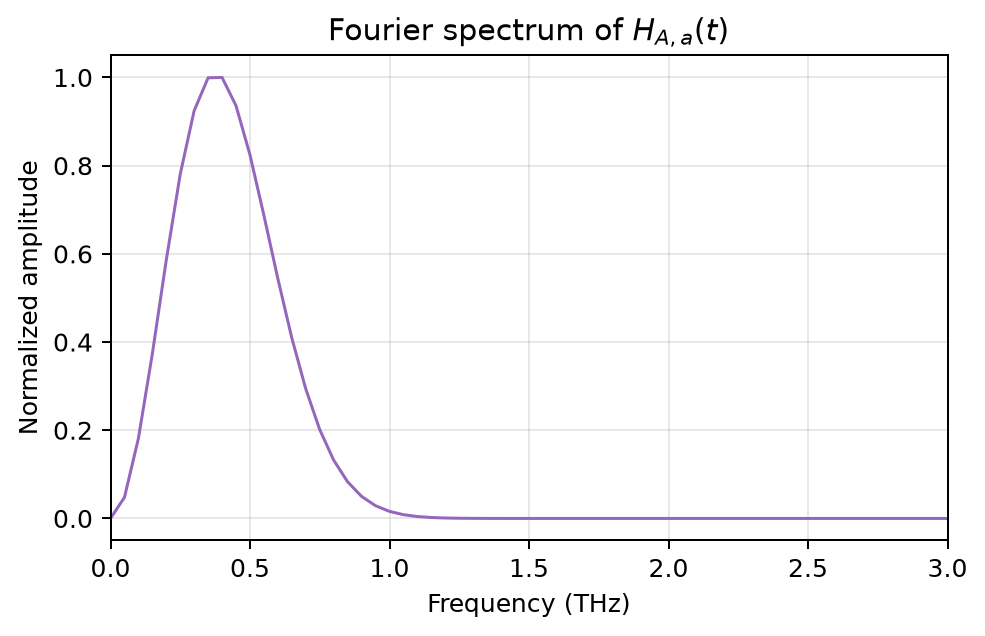

In [55]:
# Fourier spectrum of the a-axis THz field. With time in ps, frequency is in THz.
frequency, spectrum, amplitude = rfft_spectrum(
    tlist, H_single[:, 0], normalize=True, remove_mean=True
)

fig, ax = plt.subplots(figsize=(6, 3.5), dpi=180)
ax.plot(frequency, amplitude, color="tab:purple", lw=1.2)
ax.set(
    xlabel="Frequency (THz)",
    ylabel="Normalized amplitude",
    title="Fourier spectrum of $H_{A,a}(t)$",
)
ax.set_xlim([0,3])
ax.grid(alpha=0.3)
plt.show()

###  Landau–Lifshitz–Gilbert (LLG) equation

In [17]:
def update_S1S2(sol, Stot):
    S1b, S1c, S2b, S2c = np.asarray(sol, dtype=float)
    S1a_sq = Stot**2 - S1b**2 - S1c**2
    S2a_sq = Stot**2 - S2b**2 - S2c**2

    tolerance = 1e-12 * Stot**2

    if S1a_sq < -tolerance:
        raise ValueError("The S1a exceed the Stot")
    # if S2a_sq < -tolerance:
    #     raise ValueError("The S2a exceed the Stot")
    if S2a_sq < -tolerance:
        raise ValueError("The S2a exceed the Stot")

    S1a =  np.sqrt(max(S1a_sq, 0.0)) # S1a is positive
    S2a = -np.sqrt(max(S2a_sq, 0.0)) # S2a is negative
    S1 = np.array([S1a, S1b, S1c])
    S2 = np.array([S2a, S2b, S2c])
    
    return S1, S2

def LLG_S1S2_dynamics(t, sol, Ham_params, alpha, pulse_params, pulse_func):
    """
        Four-component LLG RHS compatible with scipy.integrate.solve_ivp.
    """
    S1, S2 = update_S1S2(sol, Ham_params["Stot"]) # dimensionless

    # internal fields
    H1_internal, H2_internal = effective_fields_no_external(S1, S2, Ham_params)
    H1_internal = H1_internal * 1.51927 # unit is ps^-1
    H2_internal = H2_internal * 1.51927 # unit is ps^-1

    # external field
    H_external = single_thz_pulse(t, pulse_params, pulse_func) # unit is Tesla
    H_external = H_external * 0.176086 # unit is ps^-1

    def llg(S, H_eff):
        precession = np.cross(H_eff, S)
        damping = np.cross(S, precession) / Ham_params["Stot"]
        return 1 / (1 + alpha**2) * (precession + alpha * damping)

    dS1_dt = llg(S1, H1_internal + H_external)
    dS2_dt = llg(S2, H2_internal + H_external)

    # Only the independent b and c components are integrated.
    return np.array([dS1_dt[1], dS1_dt[2], dS2_dt[1], dS2_dt[2]])

In [56]:
# simulate coherent dynamics without damping
alpha = 0.0

# time list
start_time = - 3
end_time = + 27
time_list = np.linspace(start_time, end_time, 2**9)  # ps

# initial conditions: canted AFM ground state
nn = Ham_params["nn"]
Jex = Ham_params["Jex"]
Db = Ham_params["Dvec"][1]
Ka, _, Kc = Ham_params["Kvec"]
if Ka > Kc:
  beta0 = 0.5 * np.arctan2(nn * Db, nn * Jex + Ka - Kc)
  S1_eq = Ham_params["Stot"] * np.array([np.cos(beta0), 0.0, np.sin(beta0)])
  S2_eq = Ham_params["Stot"] * np.array([-np.cos(beta0), 0.0, np.sin(beta0)])
elif Ka < Kc:
  beta0 = 0.5 * np.arctan2(nn * Db, nn * Jex - Ka + Kc)
  S1_eq = Ham_params["Stot"] * np.array([np.sin(beta0), 0.0, -np.cos(beta0)])
  S2_eq = Ham_params["Stot"] * np.array([np.sin(beta0), 0.0, np.cos(beta0)])
else:
  print("Ka = Kc, the two configurations are degenerate")

sol0 = np.array([S1_eq[1], S1_eq[2], S2_eq[1], S2_eq[2]])

### with single THz pulse & its magnetic field component along a axes
the quasi-ferromagnetic (qFM) mode can only be resonantly driven by a THz field whose magnetic-field component is perpendicular to M, whereas the excitation of the quasi-antiferromagnetic (qAFM) mode requires a magnetic-field com-ponent along M

In [57]:
pulse_params["state"] = "on"
pulse_params["polarization"] = np.array([1.0, 0.0, 0.0]) # along a axes

sol_on = solve_ivp(
    LLG_S1S2_dynamics,
    (time_list[0], time_list[-1]),
    sol0,
    t_eval=time_list,
    args=(Ham_params, alpha, pulse_params, d2gdt2_pulse),
    method="DOP853",
    rtol=1e-9,
    atol=1e-11,
    max_step=0.01,
)

S1_on = np.empty((time_list.size, 3))
S2_on = np.empty((time_list.size, 3))
for index, state in enumerate(sol_on.y.T):
    S1_on[index], S2_on[index] = update_S1S2(state, Ham_params["Stot"])

M_on = (S1_on + S2_on)

Maximum |M(t) - M(0)|: 1.355e-03


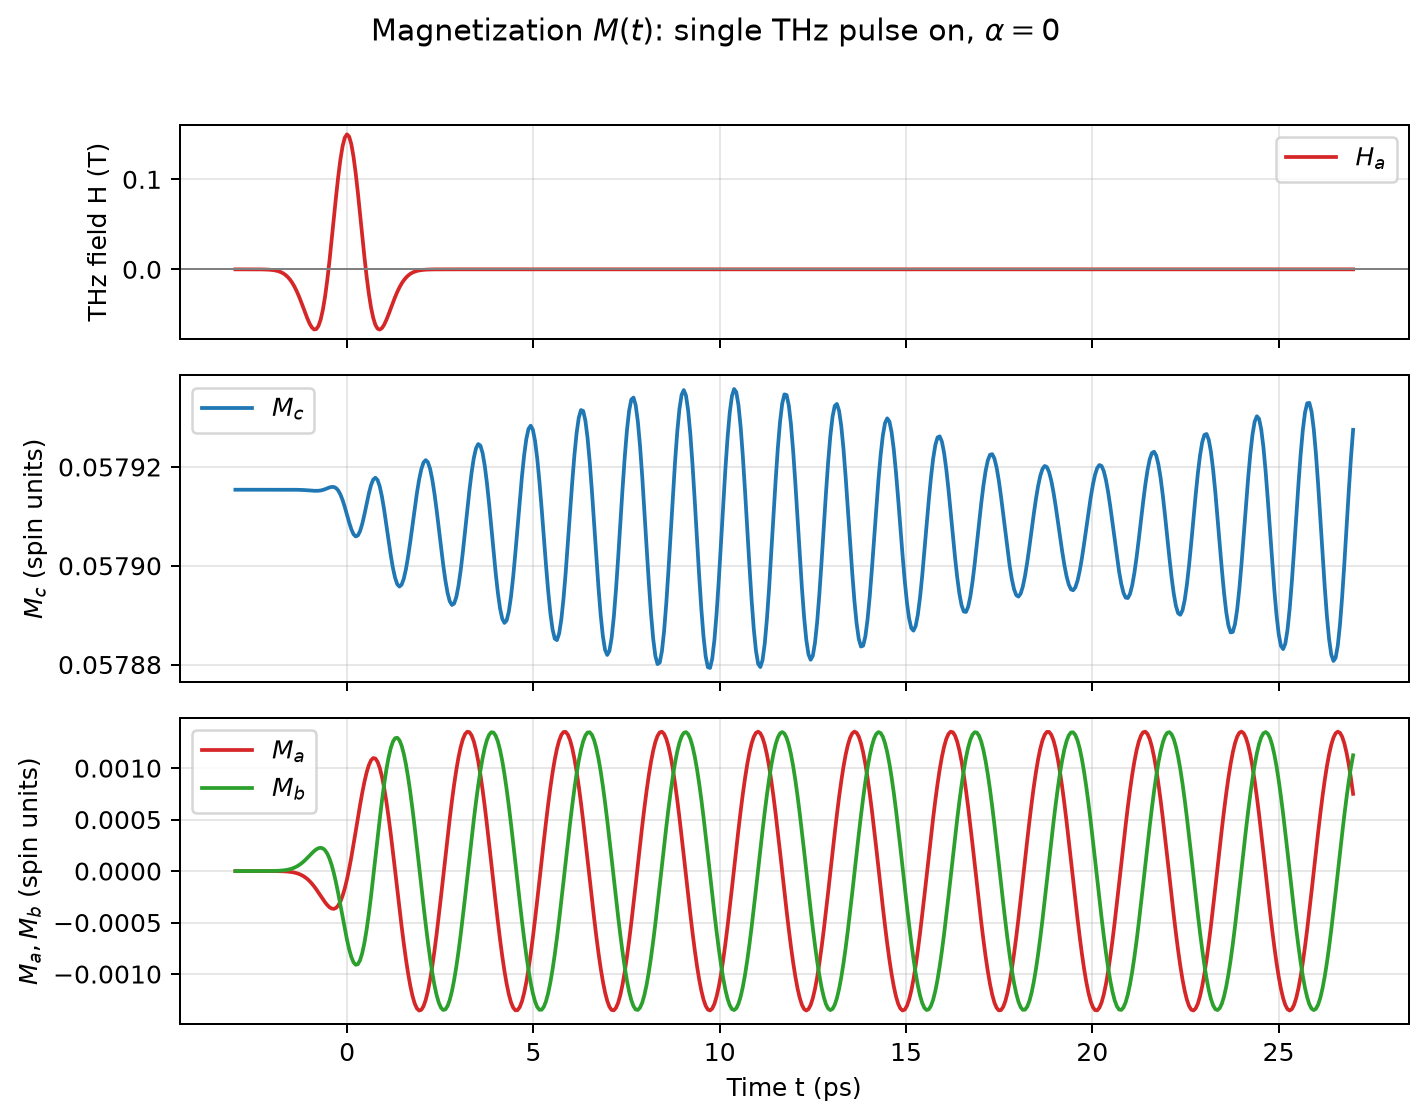

In [58]:
H_drive = single_thz_pulse(time_list, pulse_params, d2gdt2_pulse)
fig, (ax_h, ax_c, ax_ab) = plt.subplots(
    3, 1, figsize=(8, 6.3), dpi=180, sharex=True,
    gridspec_kw={"height_ratios": [0.7, 1.0, 1.0]},
)
fig.suptitle(r"Magnetization $M(t)$: single THz pulse on, $\alpha = 0$")

for component, color, component_label in zip(range(3), ["tab:red", "tab:green", "tab:blue"], [r"$H_a$", r"$H_b$", r"$H_c$"]):
    if np.any(np.abs(H_drive[:, component]) > 0):
        ax_h.plot(time_list, H_drive[:, component], color=color, label=component_label)
ax_h.axhline(0, color="gray", lw=0.8)
ax_h.set_ylabel("THz field H (T)")
ax_h.grid(alpha=0.3)
ax_h.legend()

ax_c.plot(time_list, M_on[:, 2], color="tab:blue", label=r"$M_c$")
ax_c.set_ylabel(r"$M_c$ (spin units)")
ax_c.grid(alpha=0.3)
ax_c.legend()

ax_ab.plot(time_list, M_on[:, 0], color="tab:red", label=r"$M_a$")
ax_ab.plot(time_list, M_on[:, 1], color="tab:green", label=r"$M_b$")
ax_ab.set(xlabel="Time t (ps)", ylabel=r"$M_a, M_b$ (spin units)")
ax_ab.grid(alpha=0.3)
ax_ab.legend()
fig.tight_layout(rect=[0, 0, 1, 0.96])

print(f"Maximum |M(t) - M(0)|: {np.max(np.abs(M_on - M_on[0])):.3e}")

#### Fourier analysis

In [59]:
frequency, spectrum, amplitude = rfft_spectrum(time_list, M_on, normalize = False, remove_mean = True)

max amplitude: 0.249122
max frequency: 0.399219 THz


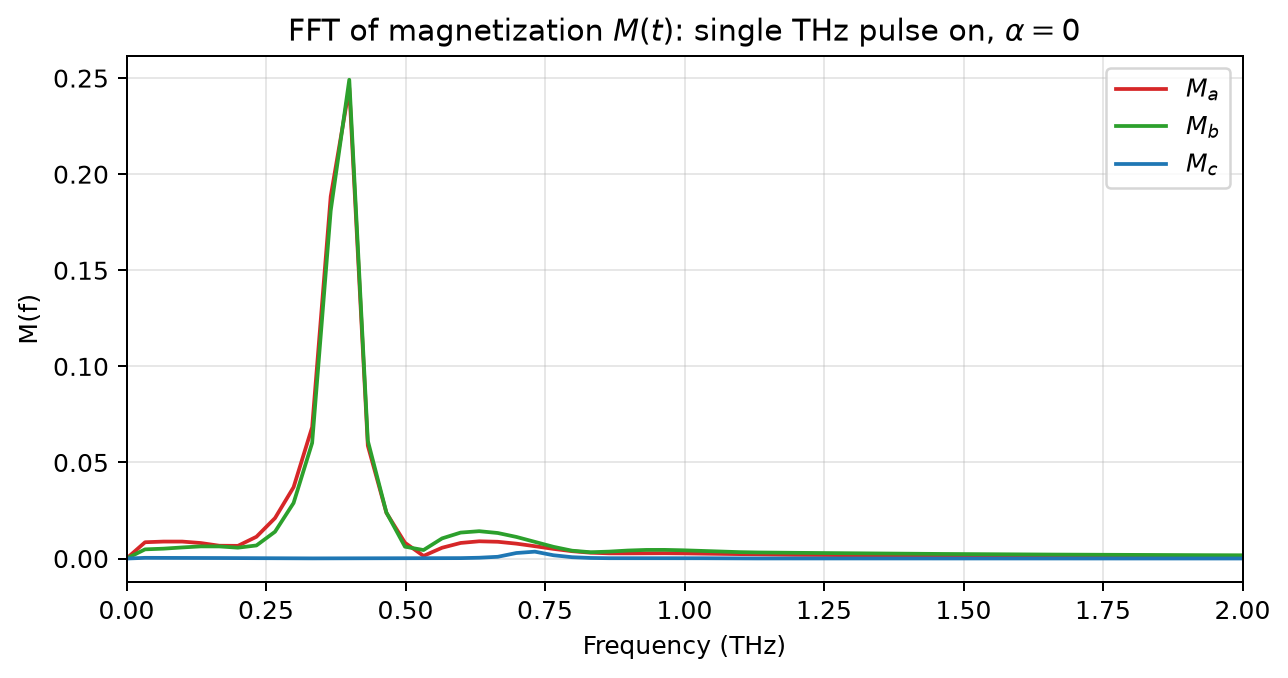

In [60]:
fig, ax = plt.subplots(figsize=(8, 3.8), dpi=180)
ax.plot(frequency, amplitude[:,0], color="tab:red", label=r"$M_a$")
ax.plot(frequency, amplitude[:, 1], color="tab:green", label=r"$M_b$")
ax.plot(frequency, amplitude[:, 2], color="tab:blue", label=r"$M_c$")
ax.set_xlim([0, 2])
# ax.set_ylim([0, 0.15])
ax.set_xlabel("Frequency (THz)")
ax.set_ylabel("M(f)")
ax.set_title(r"FFT of magnetization $M(t)$: single THz pulse on, $\alpha = 0$")
ax.grid(alpha=0.3)
ax.legend();

max_index = np.unravel_index(np.argmax(amplitude), amplitude.shape)
max_frequency = frequency[max_index[0]]
max_amplitude = amplitude[max_index]

print(f"max amplitude: {max_amplitude:.6g}")
print(f"max frequency: {max_frequency:.6g} THz")

### with single THz pulse & its magnetic field component along c axes
the quasi-ferromagnetic (qFM) mode can only be resonantly driven by a THz field whose magnetic-field component is perpendicular to M, whereas the excitation of the quasi-antiferromagnetic (qAFM) mode requires a magnetic-field com-ponent along M

In [61]:
pulse_params["state"] = "on"
pulse_params["polarization"] = np.array([0.0, 0.0, 1.0]) # along c axes

sol_on = solve_ivp(
    LLG_S1S2_dynamics,
    (time_list[0], time_list[-1]),
    sol0,
    t_eval=time_list,
    args=(Ham_params, alpha, pulse_params, d2gdt2_pulse),
    method="DOP853",
    rtol=1e-9,
    atol=1e-11,
    max_step=0.01,
)

S1_on = np.empty((time_list.size, 3))
S2_on = np.empty((time_list.size, 3))
for index, state in enumerate(sol_on.y.T):
    S1_on[index], S2_on[index] = update_S1S2(state, Ham_params["Stot"])

M_on = (S1_on + S2_on)

Maximum |M(t) - M(0)|: 1.607e-03


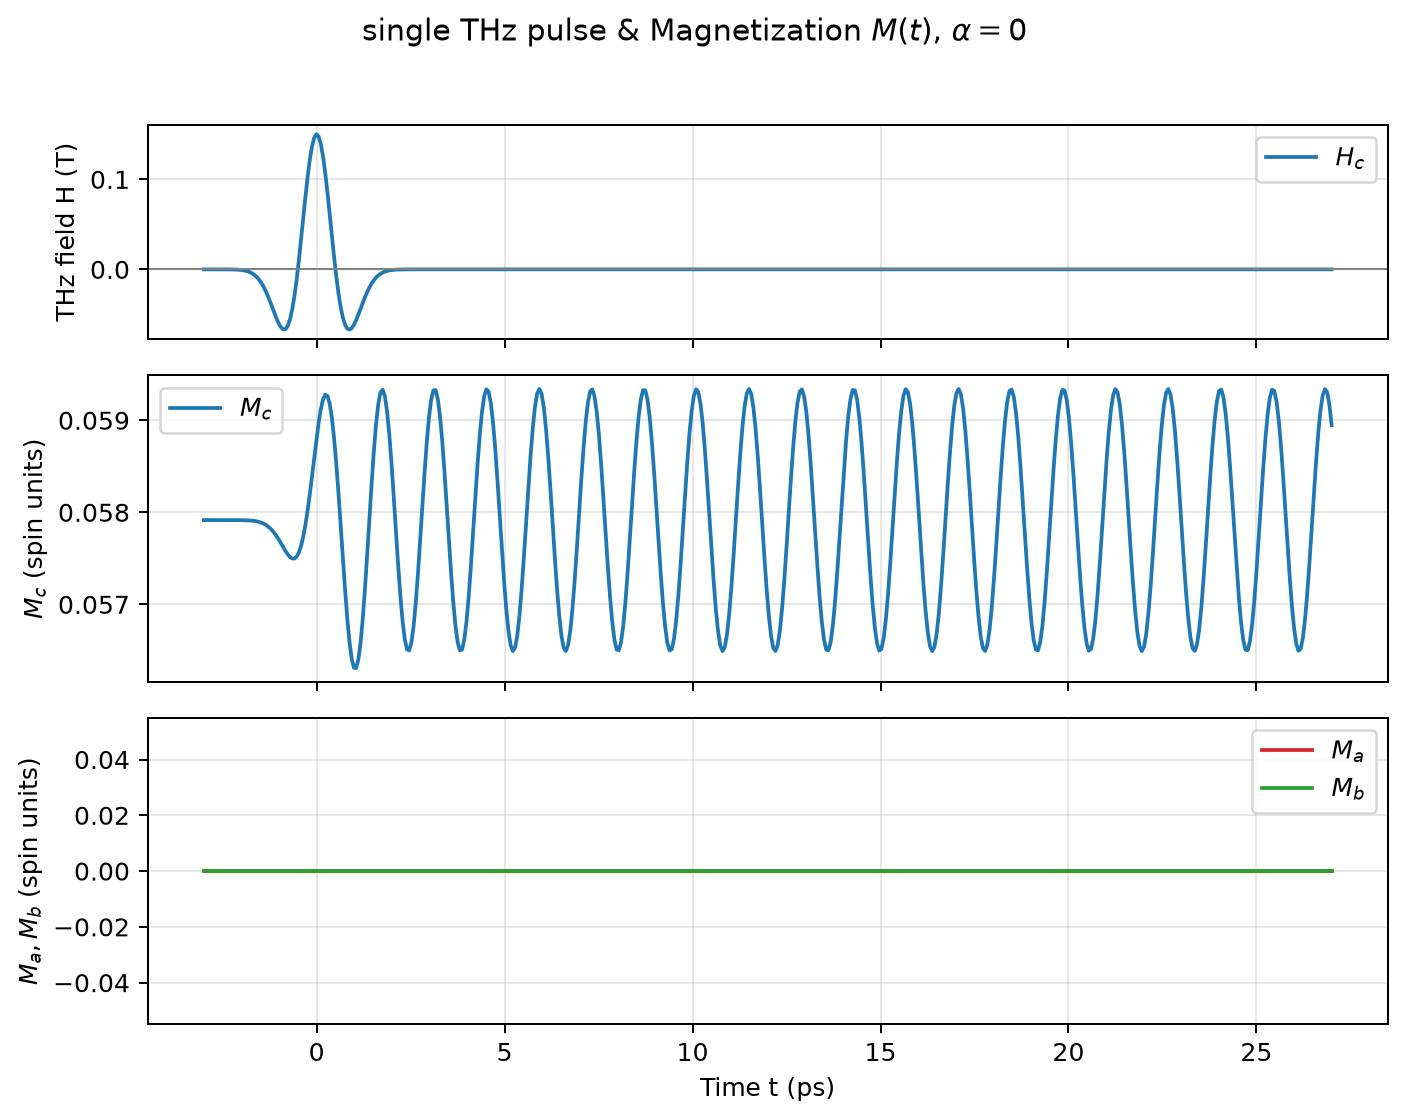

In [62]:
H_drive = single_thz_pulse(time_list, pulse_params, d2gdt2_pulse)
fig, (ax_h, ax_c, ax_ab) = plt.subplots(
    3, 1, figsize=(8, 6.3), dpi=180, sharex=True,
    gridspec_kw={"height_ratios": [0.7, 1.0, 1.0]},
)
fig.suptitle(r"single THz pulse & Magnetization $M(t)$, $\alpha = 0$")

for component, color, component_label in zip(range(3), ["tab:red", "tab:green", "tab:blue"], [r"$H_a$", r"$H_b$", r"$H_c$"]):
    if np.any(np.abs(H_drive[:, component]) > 0):
        ax_h.plot(time_list, H_drive[:, component], color=color, label=component_label)
ax_h.axhline(0, color="gray", lw=0.8)
ax_h.set_ylabel("THz field H (T)")
ax_h.grid(alpha=0.3)
ax_h.legend()

ax_c.plot(time_list, M_on[:, 2], color="tab:blue", label=r"$M_c$")
ax_c.set_ylabel(r"$M_c$ (spin units)")
ax_c.grid(alpha=0.3)
ax_c.legend()

ax_ab.plot(time_list, M_on[:, 0], color="tab:red", label=r"$M_a$")
ax_ab.plot(time_list, M_on[:, 1], color="tab:green", label=r"$M_b$")
ax_ab.set(xlabel="Time t (ps)", ylabel=r"$M_a, M_b$ (spin units)")
ax_ab.grid(alpha=0.3)
ax_ab.legend()
fig.tight_layout(rect=[0, 0, 1, 0.96])

print(f"Maximum |M(t) - M(0)|: {np.max(np.abs(M_on - M_on[0])):.3e}")

In [63]:
frequency, spectrum, amplitude = rfft_spectrum(time_list, M_on, normalize = False, remove_mean = True)

max amplitude: 0.242484
max frequency: 0.731901 THz


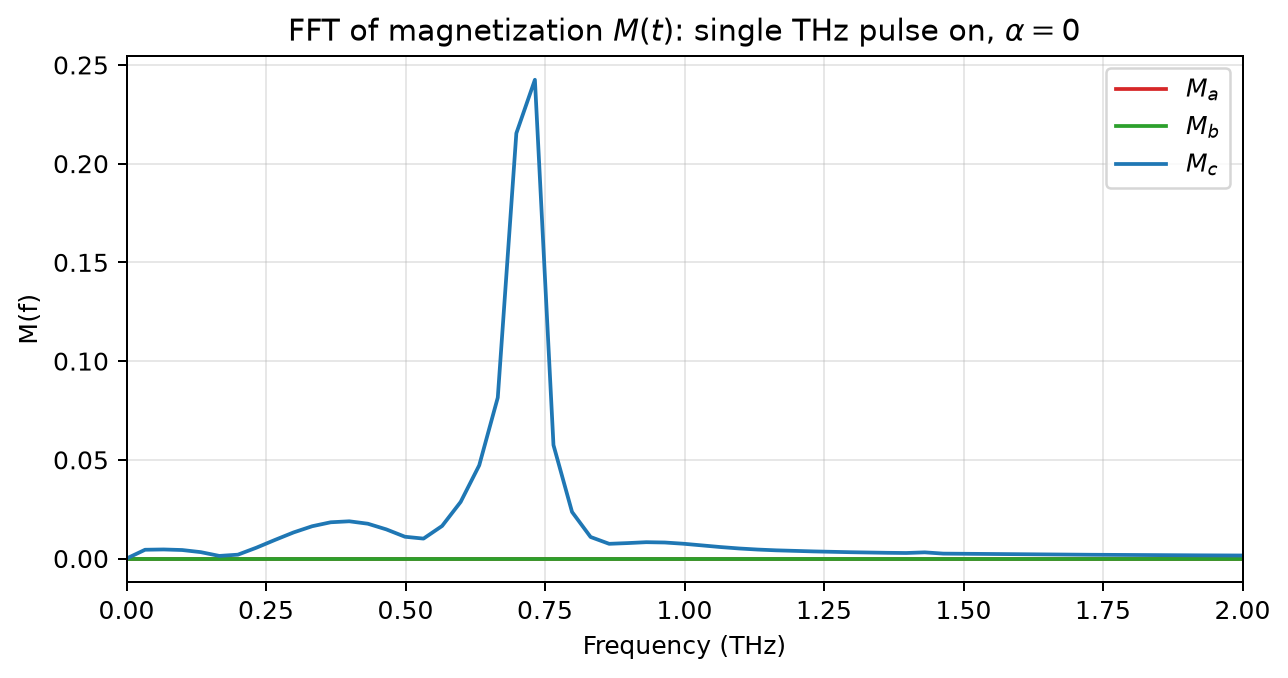

In [64]:
fig, ax = plt.subplots(figsize=(8, 3.8), dpi=180)
ax.plot(frequency, amplitude[:,0], color="tab:red", label=r"$M_a$")
ax.plot(frequency, amplitude[:, 1], color="tab:green", label=r"$M_b$")
ax.plot(frequency, amplitude[:, 2], color="tab:blue", label=r"$M_c$")
ax.set_xlim([0, 2])
# ax.set_ylim([0, 0.15])
ax.set_xlabel("Frequency (THz)")
ax.set_ylabel("M(f)")
ax.set_title(r"FFT of magnetization $M(t)$: single THz pulse on, $\alpha = 0$")
ax.grid(alpha=0.3)
ax.legend();

max_index = np.unravel_index(np.argmax(amplitude), amplitude.shape)
max_frequency = frequency[max_index[0]]
max_amplitude = amplitude[max_index]

print(f"max amplitude: {max_amplitude:.6g}")
print(f"max frequency: {max_frequency:.6g} THz")